# **Лабораторна робота №2**
## **Зниження розмірності, кластеризація та класифікація текстових даних**
***Студент:*** Мельник Владислав

***Група:*** ФБ-61мп

***Датасет для завдання 1-2:*** TON-IoT Network Dataset

***Текстовий датасет для завдання 3:*** Scam and Non-Scam Call Conversation Dataset


# **Мета роботи**

***Мета:*** ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.
# **1. Зниження розмірності та візуалізація даних**
## **1.1. Підготовка середовища**
Для виконання роботи використано Python та бібліотеки NumPy, Pandas, Matplotlib, Seaborn і Scikit-learn. Вони забезпечують обробку даних, навчання моделей та візуалізацію результатів.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, silhouette_score, adjusted_rand_score)
from sklearn.cluster import KMeans
print("Бібліотеки завантажено")

Бібліотеки завантажено


## **1.2. Завантаження датасету TON-IoT**
Для перших двох завдань використано TON-IoT Network Dataset із лабораторної роботи №1. Стовпець label містить мітки класів: 0 — нормальний трафік, 1 — атака. Поле type вказує на тип трафіку.

In [48]:
from pathlib import Path
path = Path('/content/train_test_network.csv')
if not path.exists():
    path = Path('train_test_network.csv')
if not path.exists():
    raise FileNotFoundError("Спочатку завантажте train_test_network.csv через панель Файли у Colab!")
df = pd.read_csv(path)
print("Розмір таблиці:", df.shape)
print(df.columns)
print("Розподіл label:")
print(df['label'].value_counts(dropna=False))
display(df.head())

Розмір таблиці: (211043, 44)
Index(['src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service',
       'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes',
       'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query',
       'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA',
       'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed',
       'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth',
       'http_method', 'http_uri', 'http_version', 'http_request_body_len',
       'http_response_body_len', 'http_status_code', 'http_user_agent',
       'http_orig_mime_types', 'http_resp_mime_types', 'weird_name',
       'weird_addl', 'weird_notice', 'label', 'type'],
      dtype='object')
Розподіл label:
label
1    161043
0     50000
Name: count, dtype: int64


,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


У наборі даних міститься 211 043 записи та 44 стовпці. Нормальному трафіку відповідають 50 000 записів, атакам — 161 043. Через нерівномірність класів якість Random Forest оцінювалася не лише за Accuracy, а й за Precision, Recall, F1-score та матрицею помилок.
## **1.3. Попередня обробка даних**
Перед навчанням моделей із набору ознак вилучено label і type. Стовпець type не використано, оскільки він безпосередньо пов'язаний із цільовою змінною. Таким чином, для аналізу залишено 42 ознаки.

Дані розділено на навчальну (80%) і тестову (20%) вибірки зі збереженням часток класів. Категоріальні значення закодовано за допомогою OrdinalEncoder, налаштованого на навчальній вибірці. Пропущені числові значення замінено медіанами навчальних даних. Після цього ознаки стандартизовано методом StandardScaler.

Порядкове кодування категорій має обмеження: близькі числові коди не обов'язково означають близькість самих категорій. Це потрібно враховувати під час інтерпретації PCA та K-Means.

In [49]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# Відокремлення ознак і цільової змінної
features = df.drop(
    columns=['label', 'type'],
    errors='ignore'
).copy()

y = df['label'].astype(int)

# Розподіл до навчання перетворень
train_raw, test_raw, y_train, y_test = train_test_split(
    features, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cat_cols = features.select_dtypes(
    include=['object', 'category']
).columns.tolist()

num_cols = [
    c for c in features.columns if c not in cat_cols
]

# Числові ознаки
X = pd.DataFrame(index=features.index)

for col in num_cols:
    train_values = pd.to_numeric(
        train_raw[col], errors='coerce'
    ).replace([np.inf, -np.inf], np.nan)

    median = train_values.median()
    if pd.isna(median):
        median = 0.0

    X[col] = pd.to_numeric(
        features[col], errors='coerce'
    ).replace(
        [np.inf, -np.inf], np.nan
    ).fillna(median)

# Категоріальні ознаки
if cat_cols:
    encoder = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )

    encoder.fit(
        train_raw[cat_cols].fillna('missing').astype(str)
    )

    X[cat_cols] = encoder.transform(
        features[cat_cols].fillna('missing').astype(str)
    )

# Зберігаємо порядок ознак
X = X[features.columns]

X_train = X.loc[train_raw.index]
X_test = X.loc[test_raw.index]

# Масштабування
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Кількість ознак:", X.shape[1])
print("Train:", X_train_s.shape)
print("Test:", X_test_s.shape)


Кількість ознак: 42
Train: (168834, 42)
Test: (42209, 42)


## **1.4. Класифікація до PCA**
Для навчання отримано 168 834 записи, для тестування — 42 209. Кількість вхідних ознак становить 42. Обрано Random Forest, оскільки в лабораторній роботі 1 ця модель показала найвищу точність на TON-IoT.

Використано 100 дерев рішень (n_estimators=100) і random_state=42. Час навчання вимірювався лише для методу fit, без попередньої обробки даних і побудови прогнозів. Такий самий спосіб вимірювання використано й після PCA.

In [50]:
baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
t0 = time.perf_counter()
baseline.fit(X_train_s, y_train)
t_before = time.perf_counter() - t0
pred_before = baseline.predict(X_test_s)
acc_before = accuracy_score(y_test, pred_before)
print("Ознак до PCA:", X_train_s.shape[1])
print(f"Accuracy до PCA: {acc_before:.6f}")
print(f"Час навчання до PCA: {t_before:.3f} с")

Ознак до PCA: 42
Accuracy до PCA: 1.000000
Час навчання до PCA: 13.535 с


***Додаткова перевірка якості Random Forest до PCA.***
За матрицею помилок модель правильно розпізнала 10 000 записів нормального трафіку і 32 209 записів атак. Помилок FP і FN не зафіксовано. На цій тестовій вибірці Accuracy, Precision, Recall та F1-score дорівнюють 1,00.

Додатково перевірено, чи є однакові за вхідними ознаками записи в навчальній і тестовій частинах. Таких тестових записів виявлено 5099, тобто 12,08%. Це не доводить витікання міток класів, проте могло вплинути на результат. Тому точність 100% не варто розглядати як гарантію такої самої якості на новому трафіку.

Random Forest до PCA:

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     10000
      Attack       1.00      1.00      1.00     32209

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



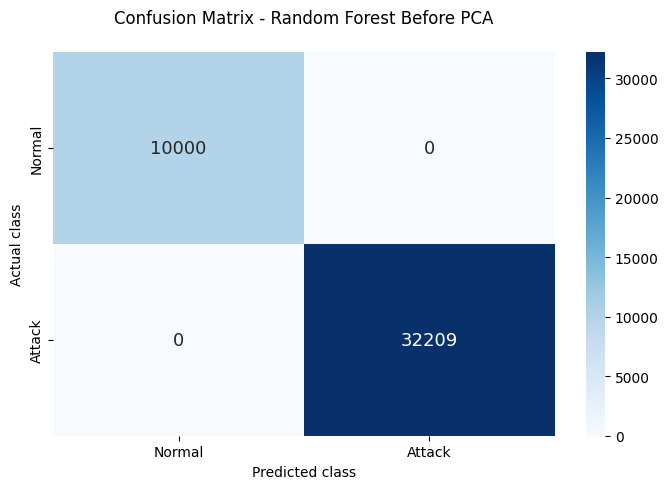


Перевірка повторення записів:
Тестових записів, що збігаються з навчальними: 5099
Частка таких записів: 12.08%


In [51]:

# 1. Результати класифікації Random Forest до PCA
print("Random Forest до PCA:")
print()

print(classification_report(
    y_test,
    pred_before,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

# 2. Побудова матриці помилок
cm = confusion_matrix(
    y_test,
    pred_before,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack'],
    annot_kws={'size': 13}
)

plt.title('Confusion Matrix - Random Forest Before PCA\n')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')

plt.tight_layout()
plt.show()

# 3. Перевірка однакових записів у train і test
train_rows = pd.util.hash_pandas_object(
    X_train, index=False
)

test_rows = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap = test_rows.isin(set(train_rows))

print()
print("Перевірка повторення записів:")
print(
    "Тестових записів, що збігаються "
    "з навчальними:", overlap.sum()
)

print(
    "Частка таких записів:",
    f"{overlap.mean() * 100:.2f}%"
)



## **1.5. Застосування PCA та повторна класифікація**
До PCA Random Forest досяг Accuracy = 100%, а час навчання становив 13,535 с. Для зменшення кількості ознак застосовано PCA зі збереженням не менш ніж 95% дисперсії. Параметри PCA визначено на навчальних даних, після чого отримане перетворення застосовано до тестових.

Для порівняння використано Random Forest із тими самими параметрами та тим самим поділом даних. Час застосування PCA і час навчання класифікатора вимірювалися окремо.

In [52]:
t_pca_start = time.perf_counter()
pca = PCA(n_components=0.95, svd_solver='full')
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)
t_pca = time.perf_counter() - t_pca_start
after = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
t0 = time.perf_counter()
after.fit(X_train_pca, y_train)
t_after = time.perf_counter() - t0
pred_after = after.predict(X_test_pca)
acc_after = accuracy_score(y_test, pred_after)
compare = pd.DataFrame({
    "Варіант": ['До PCA', 'Після PCA'],
    "Кількість ознак/компонент": [X_train_s.shape[1], X_train_pca.shape[1]],
    "Accuracy": [acc_before, acc_after],
    "Час навчання, с": [t_before, t_after]
})
display(compare)
print("Пояснена дисперсія:", round(pca.explained_variance_ratio_.sum(), 4))
print("Зменшення розмірності, %:", round(100*(1-X_train_pca.shape[1]/X_train_s.shape[1]), 2))
print(f"Час PCA (fit_transform train + transform test): {t_pca:.3f} с")

,Варіант,Кількість ознак/компонент,Accuracy,"Час навчання, с"
0,До PCA,42,1.000000,13.535085
1,Після PCA,24,0.999526,123.618420


Пояснена дисперсія: 0.9523
Зменшення розмірності, %: 42.86
Час PCA (fit_transform train + transform test): 0.568 с


***Матриця помилок Random Forest після PCA.***
Після PCA правильно класифіковано 9988 записів нормального трафіку та 32 201 запис атак. Водночас 12 нормальних записів віднесено до атак (FP), а 8 записів атак — до нормального трафіку (FN). Загалом отримано 20 помилок із 42 209 тестових записів, що відповідає Accuracy = 99,9526%. У таблиці Classification Report метрики округлено до 1,00, але фактично помилки є.

Random Forest після PCA:

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     10000
      Attack       1.00      1.00      1.00     32209

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



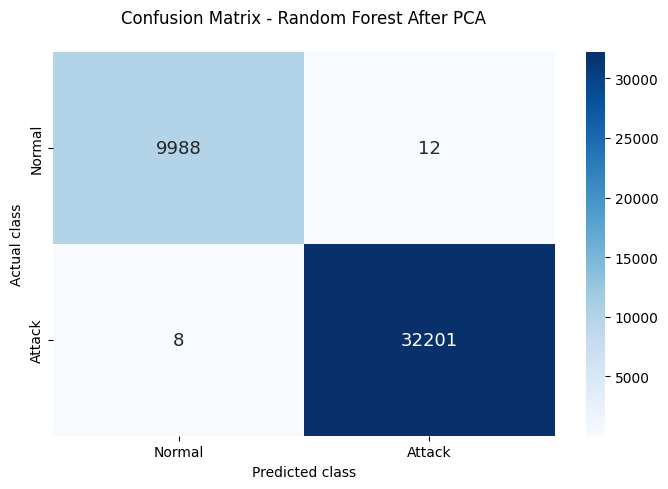

In [53]:
# Результати класифікації Random Forest після PCA
print("Random Forest після PCA:")
print()

print(classification_report(
    y_test,
    pred_after,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

# Побудова матриці помилок після PCA
cm_after = confusion_matrix(
    y_test,
    pred_after,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_after,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Attack'],
    yticklabels=['Normal', 'Attack'],
    annot_kws={'size': 13}
)

plt.title('Confusion Matrix - Random Forest After PCA\n')
plt.xlabel('Predicted class')
plt.ylabel('Actual class')

plt.tight_layout()
plt.show()


***Аналіз результатів PCA.***
PCA зменшив кількість ознак із 42 до 24 (на 42,86%) і зберіг 95,23% дисперсії. Точність Random Forest знизилася з 100% до 99,9526%, тобто на 0,0474 відсоткового пункту. При цьому час навчання зріс із 13,535 до 123,618 с. Саме перетворення PCA тривало 0,568 с.

Отже, у моєму експерименті зменшення розмірності майже не змінило точність, але не прискорило навчання. Однією з можливих причин є те, що головні компоненти поєднують вихідні ознаки, через що дерева можуть будувати інші розбиття. Втім, за одним запуском пояснити різницю в часі однозначно не можна; для цього потрібні повторні вимірювання.

## **1.6. Візуалізація методом t-SNE**
Для t-SNE відібрано 1500 мережевих записів зі збереженням пропорцій класів. Після стандартизації кількість ознак попередньо зменшено методом PCA до 20 компонент, а t-SNE застосовано для переходу до двовимірного простору. Мітки класів використовувалися тільки для позначення точок кольором.

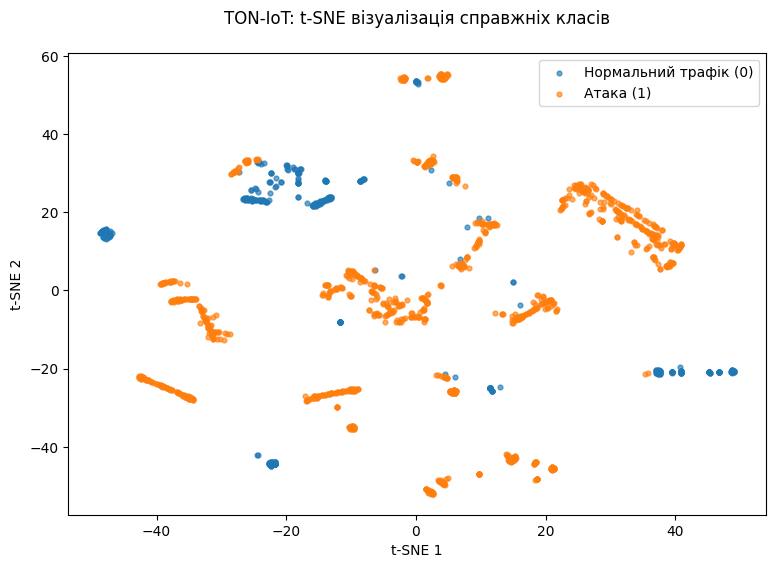

In [54]:
_, X_vis, _, y_vis = train_test_split(
    X, y, test_size=1500, random_state=42, stratify=y)
X_vis_s = StandardScaler().fit_transform(X_vis)
# попереднє PCA прискорює t-SNE (на повному наборі ознак не навчаємо класифікатор тут)
X_vis_pre = PCA(n_components=min(20, X_vis_s.shape[1]), random_state=42).fit_transform(X_vis_s)
xy = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto',
          random_state=42).fit_transform(X_vis_pre)
plt.figure(figsize=(9, 6))
for value, label in [(0, 'Нормальний трафік (0)'), (1, 'Атака (1)')]:
    mask = (y_vis.to_numpy() == value)
    plt.scatter(xy[mask, 0], xy[mask, 1], s=12, alpha=.65, label=label)
plt.title('TON-IoT: t-SNE візуалізація справжніх класів\n')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.show()

На графіку t-SNE видно декілька груп мережевих записів. Частина нормального трафіку відокремлюється від атак, проте є й ділянки, де точки двох класів розташовані поруч. Це означає, що за використаними ознаками частина записів різних класів має подібні характеристики. При цьому t-SNE переважно зберігає локальне сусідство, тому відстані між віддаленими групами не слід тлумачити буквально.

У першому завданні вдалося зменшити розмірність майже вдвічі без суттєвої втрати точності Random Forest. Однак час навчання зріс, тому сам факт скорочення кількості ознак не означає прискорення моделі.
# **2. Кластерний аналіз**
## **2.1. Підготовка даних**
Для K-Means випадково відібрано 8000 записів (random_state=17) і стандартизовано 42 ознаки. Під час кластеризації мітки label не використовувалися: їх залишено лише для перевірки результату наприкінці. Через використання підвибірки висновки стосуються насамперед цих 8000 записів.

In [55]:
_, X_cluster, _, y_cluster = train_test_split(
    X, y, test_size=8000, random_state=17)
cluster_scaler = StandardScaler()
X_cluster_s = cluster_scaler.fit_transform(X_cluster)
print("Підвибірка:", X_cluster_s.shape)
print("Мітки в K-Means не передаємо. Мітки збережені тільки для підсумкового аналізу.")

Підвибірка: (8000, 42)
Мітки в K-Means не передаємо. Мітки збережені тільки для підсумкового аналізу.


## **2.2. Визначення кількості кластерів**
Кількість кластерів перевірено для k від 2 до 6. Метод ліктя оцінює зміну Inertia — суми квадратів відстаней точок до центрів кластерів. Silhouette Score показує, наскільки добре точки відокремлені від сусідніх кластерів. Його розраховано для всіх 8000 записів, оскільки менша випадкова вибірка могла не охопити дуже малий кластер.

k = 2, фактичних кластерів: 2
k = 3, фактичних кластерів: 3
k = 4, фактичних кластерів: 4
k = 5, фактичних кластерів: 5
k = 6, фактичних кластерів: 6


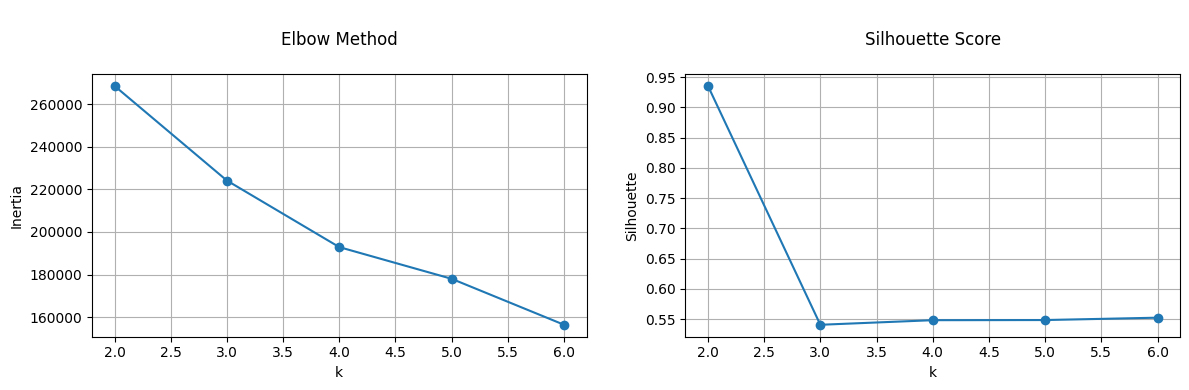

,k,Inertia,Silhouette
0,2,268631.106117,0.935467
1,3,224159.056574,0.540701
2,4,192893.253866,0.548285
3,5,178001.039367,0.548520
4,6,156416.051598,0.552419



Оптимальна кількість кластерів: 2


In [56]:
# Визначення оптимальної кількості кластерів

ks = list(range(2, 7))
inertias = []
silhouettes = []

for k in ks:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_cluster_s)

    inertias.append(model.inertia_)

    # Перевірка кількості фактичних кластерів
    unique_labels = np.unique(labels)

    print(f'k = {k}, фактичних кластерів: {len(unique_labels)}')

    if 2 <= len(unique_labels) < len(labels):
        score = silhouette_score(
            X_cluster_s,
            labels
        )
        silhouettes.append(score)
    else:
        silhouettes.append(np.nan)

# Побудова графіків
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ks, inertias, marker='o')
ax[0].set_title('\nElbow Method\n')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')
ax[0].grid(True)

ax[1].plot(ks, silhouettes, marker='o')
ax[1].set_title('\nSilhouette Score\n')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette')
ax[1].grid(True)

plt.tight_layout()
plt.subplots_adjust(wspace=0.2)
plt.show()

# Таблиця результатів
results = pd.DataFrame({
    'k': ks,
    'Inertia': inertias,
    'Silhouette': silhouettes
})

display(results)

# Вибір оптимальної кількості кластерів
if not np.all(np.isnan(silhouettes)):
    k_best = ks[int(np.nanargmax(silhouettes))]
    print('\nОптимальна кількість кластерів:', k_best)
else:
    k_best = None
    print('Не вдалося визначити k за Silhouette Score.')


При збільшенні k від 2 до 6 значення Inertia знизилося з 268 631,11 до 156 416,05. Виразного «ліктя» на графіку немає. Найвищий Silhouette Score — 0,935467 — отримано для k = 2; за більшої кількості кластерів цей показник становив приблизно 0,5407-0,5524. Тому для подальшого аналізу обрано два кластери.

Високий Silhouette Score свідчить про відокремленість груп за ознаками, але сам по собі не показує, чи відповідають вони класам «норма» та «атака».
## **2.3. Кластеризація та візуалізація**
K-Means навчено на 42 стандартизованих ознаках із k = 2. Для відображення результатів на площині застосовано PCA із двома компонентами. Кластери при цьому сформовано за всіма 42 ознаками, а не за координатами двовимірного графіка.

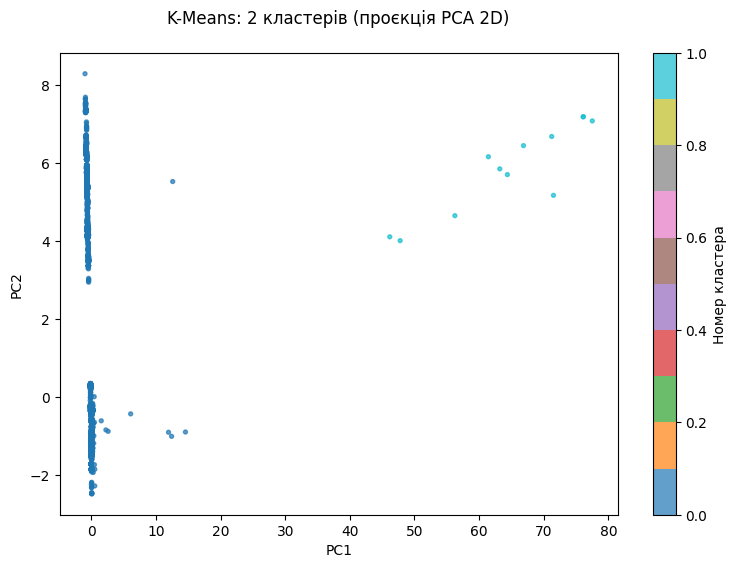

In [57]:
k_final = k_best
km = KMeans(n_clusters=k_final, n_init=10, random_state=42)
cluster_id = km.fit_predict(X_cluster_s)
xy_pca = PCA(n_components=2, random_state=42).fit_transform(X_cluster_s)
plt.figure(figsize=(9, 6))
sct = plt.scatter(xy_pca[:, 0], xy_pca[:, 1], c=cluster_id, cmap='tab10', s=8, alpha=.7)
plt.colorbar(sct, label='Номер кластера')
plt.title(f'K-Means: {k_final} кластерів (проєкція PCA 2D)\n')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()

На графіку основна частина записів зосереджена поблизу малих значень першої компоненти PC1, а невелика група розташована значно далі. Це вказує на нерівномірні розміри кластерів і можливу наявність нетипових записів. Щоб визначити, чи відповідають ці групи нормальному трафіку й атакам, потрібно порівняти їх зі справжніми мітками.
## **2.4. Порівняння зі справжніми класами**
Для такого порівняння побудовано таблицю спряженості та обчислено Adjusted Rand Index (ARI). Показник ARI дає змогу оцінити узгодженість двох розподілів без прив'язки до номерів кластерів.

label (0=норма; 1=атака),0,1
Кластер,,
0,1960,6028
1,12,0


Adjusted Rand Index (ARI): 0.0062


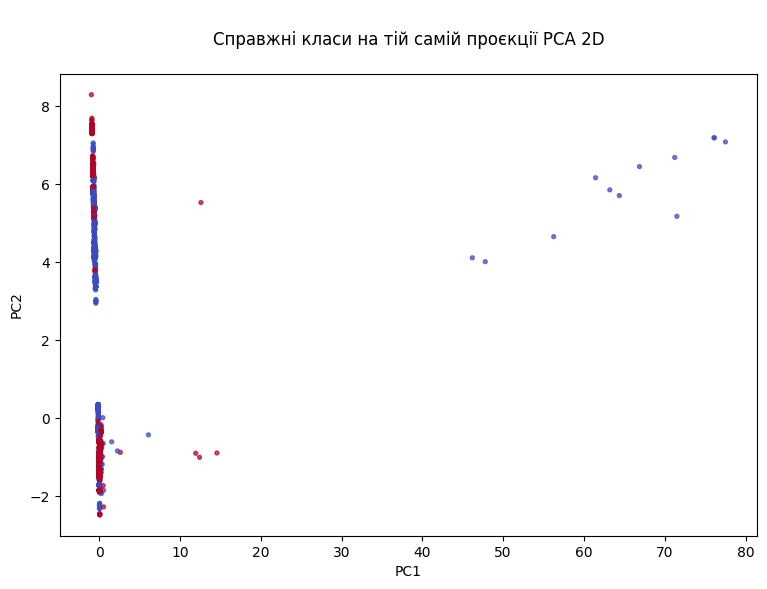

In [58]:
check = pd.DataFrame({'Кластер': cluster_id, 'Справжній клас': y_cluster.to_numpy()})
display(pd.crosstab(check['Кластер'], check['Справжній клас'],
                    rownames=['Кластер'], colnames=['label (0=норма; 1=атака)']))
print('Adjusted Rand Index (ARI):', round(adjusted_rand_score(y_cluster, cluster_id), 4))
plt.figure(figsize=(9, 6))
plt.scatter(xy_pca[:, 0], xy_pca[:, 1], c=y_cluster.to_numpy(), cmap='coolwarm', s=8, alpha=.7)
plt.title('\nСправжні класи на тій самій проєкції PCA 2D\n')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()

За таблицею спряженості кластер 0 охоплює 7988 записів: 1960 нормальних і 6028 атак. Кластер 1 містить лише 12 записів, усі вони належать до нормального трафіку. Таким чином, сформовані кластери мають суттєво різні розміри, а основна група включає спостереження обох справжніх класів.

Значення ARI = 0,0062 є близьким до нуля, що свідчить про дуже низьку узгодженість результатів K-Means зі справжнім поділом трафіку. Високий Silhouette Score за цих умов пояснюється геометричною відокремленістю малої групи спостережень, але не підтверджує можливість ототожнювати кластери з класами «норма» та «атака». Числове кодування категоріальних характеристик та можливі викиди також можуть впливати на відстані, які використовує K-Means.

У цій підвибірці K-Means не відтворив поділ на нормальний та атакувальний трафік. Це підтверджує, що кластери, сформовані за схожістю ознак, не обов'язково збігаються із заданими класами.
# **3. Обробка та класифікація текстових даних**
## **3.1. Вибір та завантаження текстових даних**
Для аналізу обрано Scam and Non-Scam Call Conversation Dataset, присвячений розпізнаванню шахрайських телефонних розмов за їхнім текстовим змістом. Використано два файли: English_NonScam.txt (клас 0, звичайні розмови) та English_Scam.txt (клас 1, шахрайські розмови). Під час завантаження встановлено, що кожен файл містить по 400 непорожніх рядків, які у цьому дослідженні розглядаються як окремі текстові записи. Це забезпечує початково збалансоване представлення класів.

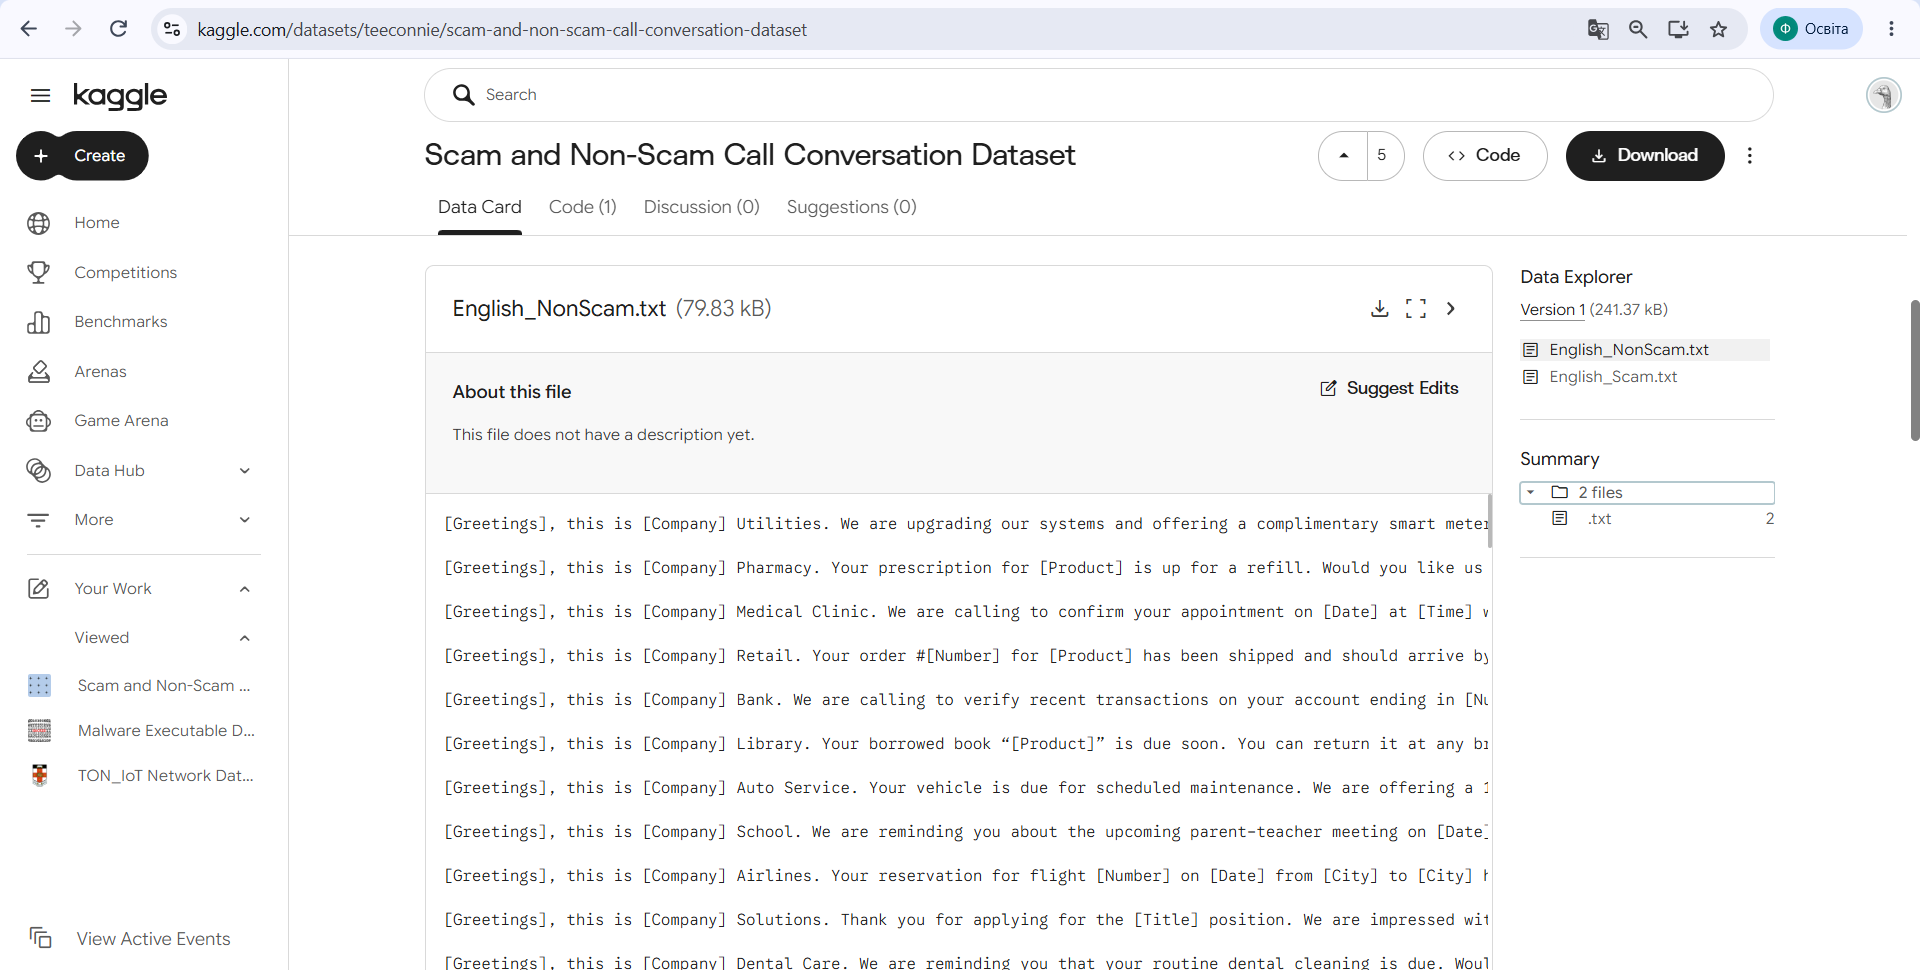

In [59]:
from pathlib import Path
import pandas as pd
import re
files = {0: 'English_NonScam.txt', 1: 'English_Scam.txt'}
rows = []
for label, filename in files.items():
    path = Path('/content') / filename
    if not path.exists():
        path = Path(filename)
    raw = path.read_text(encoding='utf-8-sig')
    lines = [s.strip() for s in raw.splitlines() if s.strip()]
    print(filename, '| непорожніх рядків:', len(lines))
    print('Перші 3 довжини рядків:', [len(s) for s in lines[:3]])
    # Один непорожній рядок = один запис лише якщо це підтверджує структура.
    if len(lines) != 400:
        raise ValueError(f'{filename}: очікується 400 записів. Перевірте роздільники у файлі; не розбивайте розмови на окремі репліки.')
    rows.extend({'text': s, 'label': label} for s in lines)
calls = pd.DataFrame(rows)
print('Розмір:', calls.shape)
print(calls.label.value_counts())
display(calls.assign(length=calls.text.str.len())[['label','length']].head())

English_NonScam.txt | непорожніх рядків: 400
Перші 3 довжини рядків: [275, 237, 223]
English_Scam.txt | непорожніх рядків: 400
Перші 3 довжини рядків: [249, 241, 200]
Розмір: (800, 2)
label
0    400
1    400
Name: count, dtype: int64


,label,length
0,0,275
1,0,237
2,0,223
3,0,215
4,0,267


Після об'єднання файлів отримано 800 текстів зі стовпцями text і label. Для повторного виконання дослідження потрібні обидва вихідні TXT-файли.
## **3.2. Передобробка текстів**
Спочатку тексти переведено до нижнього регістру. Регулярними виразами видалено позначки у квадратних дужках, цифри та розділові знаки, після чого прибрано зайві пробіли. Також перевірено порожні тексти, дублікати й записи з однаковим текстом, але різними мітками.

Для WordCloud і TF-IDF використано стандартний список англійських стоп-слів із Scikit-learn. З нього виключено no, not, never і nor, оскільки заперечення можуть змінювати зміст висловлювання. У функції clean_text стоп-слова не видаляються: вони відсіюються на наступних етапах.

In [60]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
stop_words = set(ENGLISH_STOP_WORDS) - {'no','not','never','nor'}
def clean_text(s):
    s = re.sub(r'\[[^\]]*\]', ' ', s.lower())
    s = re.sub(r'[^a-z\s]', ' ', s)
    return ' '.join(s.split())
calls['clean'] = calls.text.map(clean_text)
calls = calls[calls.clean.str.len() > 0].copy()
conflicts = calls.groupby('clean').label.nunique()
calls = calls[~calls.clean.isin(conflicts[conflicts > 1].index)]
calls = calls.drop_duplicates('clean').reset_index(drop=True)
print('Після очищення:', calls.shape)
print(calls.label.value_counts())
print('Приклад очищеного тексту:', calls.clean.iloc[0][:180])

Після очищення: (793, 3)
label
0    400
1    393
Name: count, dtype: int64
Приклад очищеного тексту: this is utilities we are upgrading our systems and offering a complimentary smart meter installation to improve service efficiency can we schedule a visit to your home this week th


Після очищення залишилося 793 тексти: 400 класу Non-scam та 393 класу Scam. Перевірка показала, що порожніх текстів і суперечливих міток не було. Видалено 7 дублікатів, які утворилися або залишилися після очищення. Саме цим пояснюється зменшення кількості записів із 800 до 793.

In [61]:
# Повторний аналіз очищення вихідних текстів

original = []

for label, filename in {
    0: 'English_NonScam.txt',
    1: 'English_Scam.txt'
}.items():

    path = Path('/content') / filename
    if not path.exists():
        path = Path(filename)

    lines = [
        line.strip()
        for line in path.read_text(
            encoding='utf-8-sig'
        ).splitlines()
        if line.strip()
    ]

    original.extend(
        {'text': line, 'label': label}
        for line in lines
    )

audit = pd.DataFrame(original)
audit['clean'] = audit['text'].map(clean_text)

empty_count = (audit['clean'].str.len() == 0).sum()

audit = audit[audit['clean'].str.len() > 0].copy()

conflicts = audit.groupby('clean')['label'].nunique()
conflict_texts = conflicts[conflicts > 1].index

conflict_count = audit['clean'].isin(
    conflict_texts
).sum()

audit = audit[~audit['clean'].isin(conflict_texts)]

duplicates_count = audit.duplicated(
    subset=['clean']
).sum()

print('Порожніх записів:', empty_count)
print('Записів із суперечливими мітками:', conflict_count)
print('Повторних записів:', duplicates_count)

print(
    'Загалом видалено:',
    empty_count + conflict_count + duplicates_count
)


Порожніх записів: 0
Записів із суперечливими мітками: 0
Повторних записів: 7
Загалом видалено: 7


## **3.3. Візуалізація текстів WordCloud**
Для кожного класу побудовано окрему хмару слів. Чим частіше слово зустрічається в текстах відповідного класу після фільтрації, тим більшим воно відображається. Хмари слів використано для початкового порівняння лексики звичайних і шахрайських розмов.

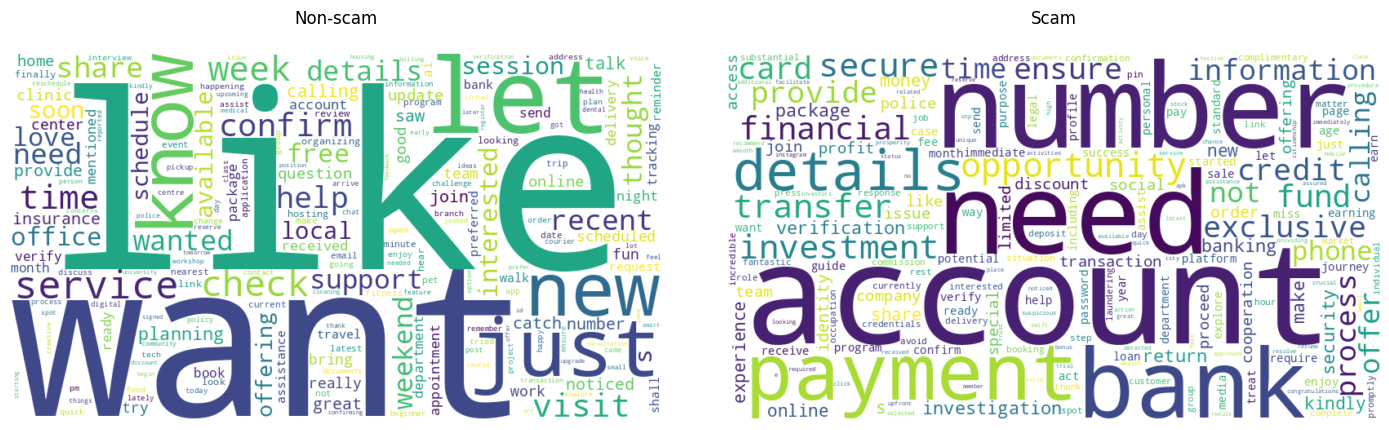

In [62]:
from wordcloud import WordCloud
fig, axes = plt.subplots(1, 2, figsize=(14,5))
for label, name, ax in zip([0,1], ['Non-scam\n','Scam\n'], axes):
    text = ' '.join(calls.loc[calls.label == label, 'clean'])
    wc = WordCloud(width=800, height=450, background_color='white', stopwords=stop_words, collocations=False, random_state=42).generate(text)
    ax.imshow(wc, interpolation='bilinear'); ax.set_title(name); ax.axis('off')
plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.show()

У хмарі Non-scam виділяються слова want, like, new, service, week, visit, confirm, пов'язані з повсякденними послугами та плануванням. У класі Scam помітні account, number, payment, bank, transfer, investment, details, secure. Вони частіше стосуються рахунків, платежів і запитів фінансової інформації.

Однак окреме слово не визначає, чи є розмова шахрайською: важливий контекст, у якому воно використане.
## **3.4. Векторизація TF-IDF та навчання класифікатора**
Тексти поділено на навчальну й тестову частини у співвідношенні 80/20 зі збереженням часток класів. Для перетворення текстів на числові ознаки використано TF-IDF з уніграмами та біграмами (ngram_range=(1, 2)). Векторизатор навчено тільки на навчальній частині, а до тестової застосовано вже готове перетворення.

Для класифікації використано Multinomial Naive Bayes. Цей алгоритм підходить для роботи з невід'ємними ознаками TF-IDF.

In [63]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
Xtr, Xte, ytr, yte = train_test_split(calls.clean, calls.label, test_size=0.2, random_state=42, stratify=calls.label)
vectorizer = TfidfVectorizer(stop_words=sorted(stop_words), ngram_range=(1,2))
A = vectorizer.fit_transform(Xtr)
B = vectorizer.transform(Xte)
model = MultinomialNB()
model.fit(A, ytr)
pred = model.predict(B)
print('Train:', A.shape)
print('Test:', B.shape)
print('Accuracy:', accuracy_score(yte,pred))
print()
print(classification_report(yte,pred,labels=[0,1],target_names=['Non-scam','Scam'],zero_division=0))

Train: (634, 12207)
Test: (159, 12207)
Accuracy: 0.9685534591194969

              precision    recall  f1-score   support

    Non-scam       1.00      0.94      0.97        80
        Scam       0.94      1.00      0.97        79

    accuracy                           0.97       159
   macro avg       0.97      0.97      0.97       159
weighted avg       0.97      0.97      0.97       159



***Аналіз результатів класифікації текстів.***
Після очищення залишилося 793 тексти: 634 використано для навчання та 159 — для тестування. Векторизація TF-IDF сформувала 12 207 ознак. Точність моделі становила 96,86%.

Для Scam отримано Precision = 0,94, Recall = 1,00 і F1-score = 0,97; для Non-scam — відповідно 1,00, 0,94 і 0,97. Значення Recall = 1,00 означає, що модель виявила всі 79 шахрайських текстів у тестовій вибірці. Проте ця вибірка невелика й містить шаблонні формулювання, тому за результатом одного тестування не можна робити висновки про таку саму ефективність на реальних дзвінках.
## **3.5. Матриця помилок**
Для перевірки помилок побудовано матрицю з фактичними класами в рядках і прогнозованими — у стовпцях. Значення 0 відповідає Non-scam, 1 — Scam.

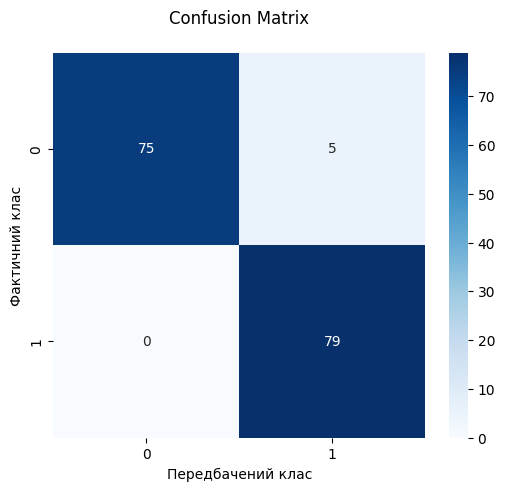

In [64]:
cm = confusion_matrix(yte,pred,labels=[0,1])
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['0','1'],yticklabels=['0','1'])
plt.xlabel('Передбачений клас'); plt.ylabel('Фактичний клас'); plt.title('Confusion Matrix\n'); plt.show()

Матриця помилок показала 75 правильно визначених звичайних розмов і 79 правильно визначених шахрайських. П'ять текстів Non-scam модель помилково віднесла до Scam (FP = 5). Пропущених шахрайських текстів не було (FN = 0). Для задачі виявлення шахрайства це важливо, хоча хибні спрацьовування також потрібно враховувати.

Після очищення текстів, TF-IDF і навчання Multinomial Naive Bayes отримано Accuracy = 96,86% на тестовій вибірці. Результат показує, що за текстом розмови можна виявляти характерні ознаки шахрайства. Водночас модель варто перевірити на незалежних реальних записах.
# **Загальні висновки**
Під час виконання лабораторної роботи було досліджено PCA, t-SNE, K-Means і класифікацію текстів. Для TON-IoT метод PCA зменшив кількість ознак із 42 до 24 зі збереженням 95,23% дисперсії. Точність Random Forest знизилася з 100% до 99,9526%, а час навчання зріс із 13,535 до 123,618 с. Таким чином, зменшення розмірності не завжди прискорює модель.

Для K-Means обрано k = 2. Попри Silhouette Score = 0,935467, значення ARI = 0,0062 вказує, що отримані кластери майже не відповідають реальним класам. У третьому завданні Multinomial Naive Bayes на основі TF-IDF досяг точності 96,86%, а Recall для Scam становив 1,00.

Основний висновок роботи полягає в тому, що високі метрики потрібно оцінювати разом із матрицями помилок, особливостями вибірки та способом підготовки даних.
# **Методичні обмеження**
Під час перевірки Random Forest виявлено 5099 із 42 209 тестових записів, які мають такі самі значення ознак, як записи навчальної вибірки. Це могло вплинути на Accuracy 100%, тому для надійної оцінки модель потрібно додатково перевірити на вибірці без таких збігів.

Для категоріальних ознак використано OrdinalEncoder, який навчався тільки на навчальних даних. Водночас таке кодування задає умовний числовий порядок категорій і може впливати на відстані, що використовуються PCA та K-Means. Також у роботі застосовано лише одну підвибірку для кластеризації та один поділ текстових даних. Для перевірки стійкості результатів варто повторити експерименти з іншими розподілами.
